In [1]:
import warnings
warnings.filterwarnings('ignore')

import sys,os
from copy import copy
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage

import numpy as np
import pandas as pd

import scanpy as sc
import anndata


mpl.rcParams['figure.dpi'] = 50
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)

sns.set_style({'axes.grid': False})

In [2]:
project_dir = '/home/xuquan/projects/pdac'
sc.settings.figdir = f'{project_dir}/figures/'
figdir = f'{project_dir}/figures/'

In [3]:
gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

plate_level_all0 = pd.read_csv(f"{project_dir}/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'



In [4]:

nichenetr = pd.read_csv(f"{project_dir}/db/nichenetr_lr_network.txt", sep='\t')
l = nichenetr['from'].tolist()
r = nichenetr['to'].tolist()
all_lr = list(zip(nichenetr['from'],nichenetr['to']))


nichenetr = pd.read_csv(f"{project_dir}/db/lr_network_hg_Lignature.txt", sep='\t')
nichenetr['from'] = nichenetr['Lgene']
nichenetr['to'] = nichenetr['Rgene']
nichenetr = nichenetr.drop_duplicates(subset=['from', 'to'], keep='first')

l = nichenetr['Lgene'].tolist()
r = nichenetr['Rgene'].tolist()
all_lr = list(zip(nichenetr['Lgene'],nichenetr['Rgene']))



In [5]:
allgenes_km = pd.read_csv(f"{project_dir}/db/allgenes_km.txt", sep='\t')
allgenes_km_logpval = allgenes_km.set_index('symbols').to_dict()['logpval']



In [149]:
# nichenetr

### ALL LR

In [6]:
sub_celltype = 'all'

adata = sc.read_h5ad(f"{project_dir}/pdac_atlas/{sub_celltype}/pdac_scpoli_reannot_clear_de.h5ad")

# sc.tl.umap(adata, n_components=3)
# adata.write_h5ad(f"{project_dir}/results/{res_dir}/{sub_celltype}/pdac_scpoli_reannot_3d.h5ad", compression="gzip")


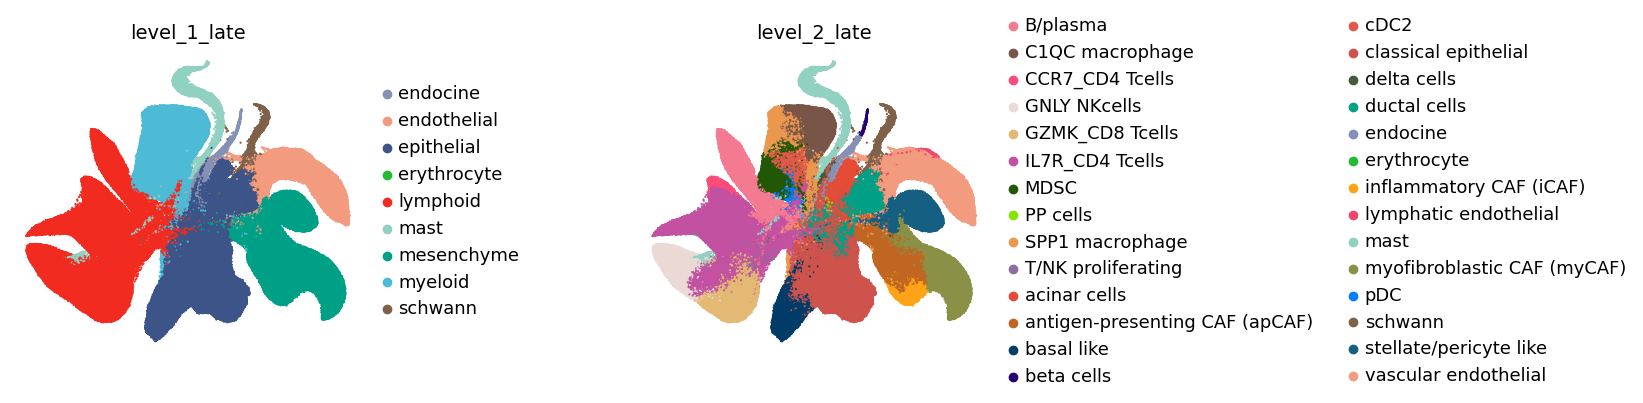

In [7]:
sc.pl.umap(adata, 
       color=['level_1_late', 'level_2_late'], 
       wspace=0.6, size=10, ncols=2, frameon=False, palette=plate_level_all)


In [8]:
ref_degenes = pd.DataFrame()
for i in adata.obs.level_1_late.unique():
    ref_degenes[i] = sc.get.rank_genes_groups_df(adata, group=i, 
                    key='wilcoxon', pval_cutoff=0.01, log2fc_min=0)['names'].head(500)

lr_genes = [i for i in l+r if i in adata.raw.var.index.tolist()]
lr_genes = list(set(lr_genes))
lr_genes_exp = adata.raw.to_adata().to_df()[lr_genes]
lr_genes_exp['level_1_late'] = adata.obs.level_1_late
lr_genes_exp_mean = lr_genes_exp.groupby('level_1_late').mean()

lr_genes_exp_mean = lr_genes_exp_mean[lr_genes_exp_mean.sum()[lr_genes_exp_mean.sum()>0.1].index.tolist()]
lr_genes_exp_mean = lr_genes_exp_mean[[i for i in lr_genes_exp_mean.columns if i in ref_degenes.values.flatten().tolist()]]



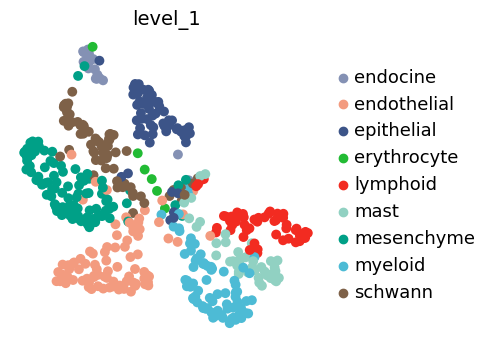

In [9]:
adata_lr = anndata.AnnData(X=lr_genes_exp_mean.T,
                        obs=lr_genes_exp_mean.T[[]],
                        var=lr_genes_exp_mean[[]])
adata_lr.obs['level_1'] = lr_genes_exp_mean.T.astype(float).idxmax(1).tolist()

sc.tl.pca(adata_lr)
sc.pp.neighbors(adata_lr, n_pcs=0, n_neighbors=15)
sc.tl.umap(adata_lr, min_dist=0.5)

sc.pl.umap(adata_lr, color=['level_1'], palette=plate_level_all,
          size=200, ncols=5, frameon=False)


In [475]:
# ref_degenes.epithelial.tolist()

In [10]:
df_pos = pd.DataFrame(adata_lr.obsm['X_umap'])
df_pos.columns=['UMAP1','UMAP2']
df_pos['gene'] = adata_lr.obs.index
df_pos['level_1'] = adata_lr.obs.level_1.tolist()

df_pos['pos'] = range(1, df_pos.shape[0]+1)
show_genes=['MIF','EGFR','SDC1','ITGA2','ITGA6','LAMB1','COL1A1','FN1','THBS1','LRP1',
           'HGF','ITGB1','TNC','COMP']+ref_degenes.head(10).values.flatten().tolist()
df_pos['show_genes']=df_pos.gene
df_pos.loc[~df_pos.gene.isin(show_genes),'show_genes']='nan'

# df_pos['level_1_c'] = [plate_level_all[adata_lr.obs.to_dict()['level_1'][i]] for i in df_pos.gene]
df_pos['level_1_c'] = [plate_level_all[i] for i in df_pos.level_1]

lrs = []
colors3 = []
for i in df_pos.gene:
    if i in l:
        lrs.append('ligand')
        colors3.append('#00A087')
    else:
        lrs.append('receptor')
        colors3.append('#4DBBD5')

df_pos['lr_c'] = colors3
df_pos['lr'] = lrs


df_pos['size'] = 100

df_pos.head()

,UMAP1,UMAP2,gene,level_1,pos,show_genes,level_1_c,lr_c,lr,size
0,-4.658107,6.650588,IL1R1,mesenchyme,1,nan,#00A087,#4DBBD5,receptor,100
1,1.179481,3.868479,PLAUR,myeloid,2,nan,#4DBBD5,#4DBBD5,receptor,100
2,-2.155613,8.733439,ITGB4,schwann,3,nan,#7E6148,#4DBBD5,receptor,100
3,-5.883230,6.902211,SDC2,mesenchyme,4,nan,#00A087,#00A087,ligand,100
4,0.703280,6.321573,CD9,schwann,5,nan,#7E6148,#00A087,ligand,100


In [11]:
de_lr0 = nichenetr[(nichenetr['from'].isin(adata_lr.obs.index.tolist()))&
        (nichenetr['to'].isin(adata_lr.obs.index.tolist()))][['from', 'to']]

de_lr = pd.DataFrame()
de_lr['from'] = [df_pos.set_index('gene').to_dict()['pos'][i] for i in de_lr0['from']]
de_lr['to'] = [df_pos.set_index('gene').to_dict()['pos'][i] for i in de_lr0['to']]



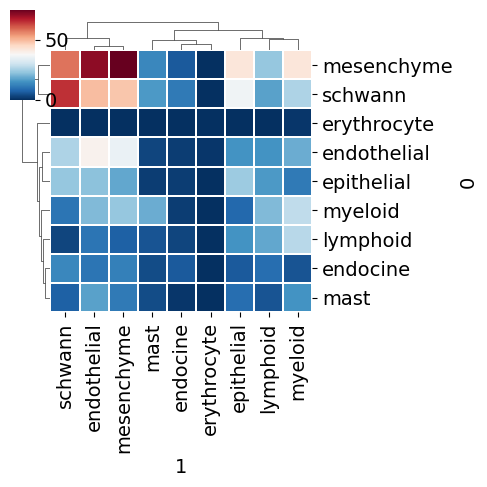

In [12]:
res_ls1 = []
res_df = pd.DataFrame()
for ct1 in ref_degenes.columns:
    for ct2 in ref_degenes.columns:
        pairs = len([i for i in all_lr if i[0] in ref_degenes[ct1].tolist() and 
                                 i[1] in ref_degenes[ct2].tolist()])
        res_ls1.append([ct1, ct2, pairs])
        
        sub_res = pd.DataFrame([i for i in all_lr if i[0] in ref_degenes[ct1].tolist() and 
                                 i[1] in ref_degenes[ct2].tolist()])
        sub_res['from'] = ct1
        sub_res['to'] = ct2
        
        res_df = pd.concat([res_df, sub_res])

res_df.columns=['L', 'R', 'Lcell', 'Rcell']

res_ls1 = pd.DataFrame(res_ls1)
res_ls1 = res_ls1.set_index(0).pivot(columns=1, values=2)

fig = sns.clustermap(res_ls1, 
#                      z_score=1, 
                     cmap='RdBu_r',dendrogram_ratio=0.1, colors_ratio=0.01,
                     linewidths=0.1,
                     figsize=(5,5))

# fig.savefig(f"{figdir}/LR_ALL_number1.pdf")


In [13]:
df_flattened = res_ls1.melt(var_name='Subject', value_name='Score', ignore_index=False).reset_index()

df_flattened.columns = ['Acceptor', 'Sender', 'Value']
# df_flattened.columns = ['Sender','Acceptor', 'Value']
df_flattened['Pair'] = df_flattened['Sender'] + ' → ' + df_flattened['Acceptor']


In [14]:
ct_order = ['epithelial', 'mesenchyme', 'endocine', 'endothelial', 
 'myeloid', 'lymphoid','erythrocyte', 'mast', 'schwann']

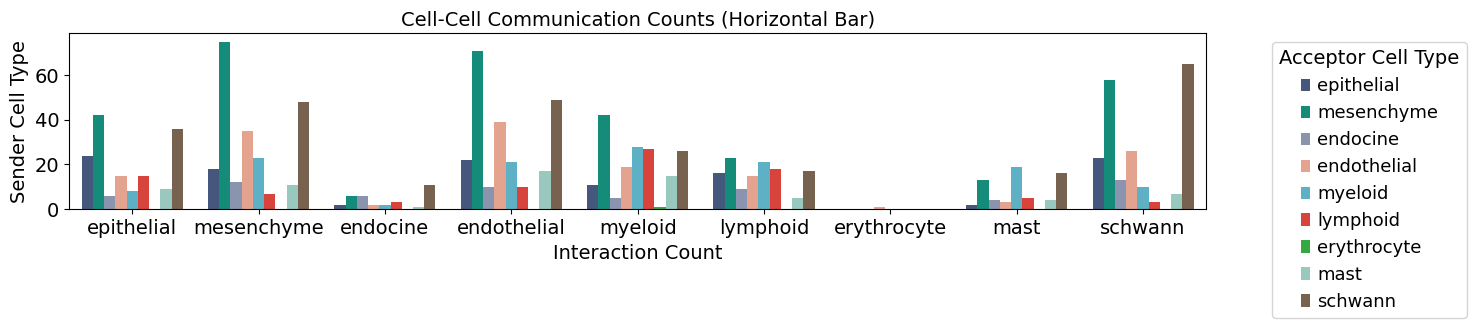

In [15]:
plt.figure(figsize=(15, 3)) # 纵向长方形画布
sns.barplot(
    data=df_flattened,
    x='Sender',      # 分组
    y='Value',       # 柱子长短
    hue='Acceptor',  # 颜色区分
    palette=plate_level_all,
    order=ct_order,
    hue_order=ct_order
)
plt.title("Cell-Cell Communication Counts (Horizontal Bar)")
plt.xlabel("Interaction Count")
plt.ylabel("Sender Cell Type")
plt.legend(title="Acceptor Cell Type", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f"/home/xuquan/projects/pdac/figures/all_lr_score.pdf", bbox_inches='tight')

plt.show()

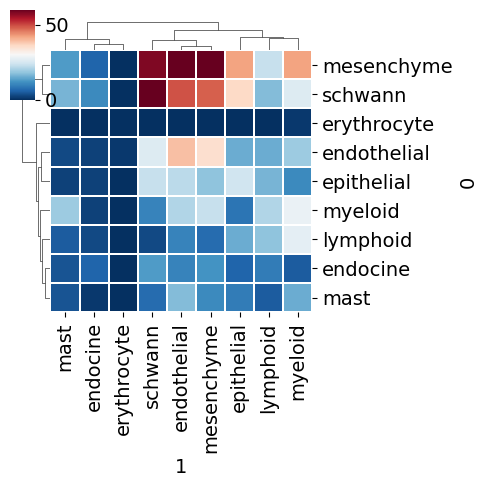

In [16]:
res_ls2 =res_ls1.copy()
res_ls2[res_ls2>60]=60

fig = sns.clustermap(res_ls2, 
                     cmap='RdBu_r',dendrogram_ratio=0.1, colors_ratio=0.01,
                     linewidths=0.1,
                     figsize=(5,5))
# fig.savefig(f"{figdir}/LR_ALL_number1.pdf")


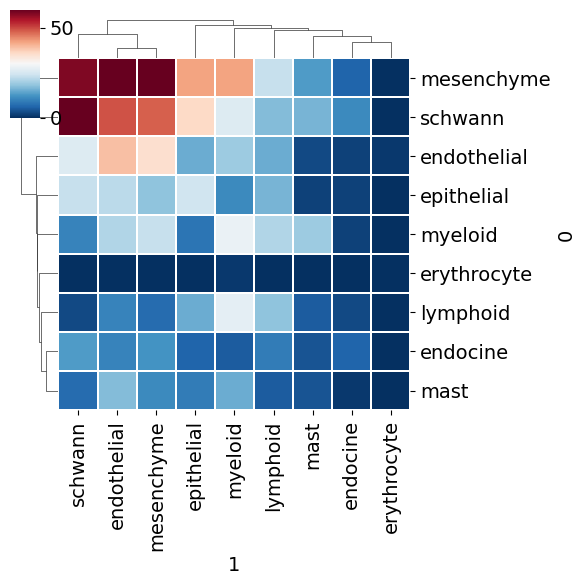

In [17]:
link1 = linkage(res_ls2.T)
link2 = linkage(res_ls2)

# link2[10][[0,1]]=link2[10][[1,0]]
# link1[7][[0,1]]=link1[7][[1,0]]

fig = sns.clustermap(res_ls2, 
                     col_linkage=link1, 
                     row_linkage=link2, 
                     row_cluster=True, 
                     col_cluster=True,
                     cmap='RdBu_r',dendrogram_ratio=0.1, colors_ratio=0.01,
                     linewidths=0.1,
                     figsize=(6,6)
                    )
# fig.savefig(f"{figdir}/LR_ALL_number1.pdf")


### Celltype LR

In [18]:
res_dir = 'run_20241130_scp'

adata_epi = sc.read_h5ad(f"{project_dir}/pdac_atlas/epithelial/pdac_scpoli_late_final2.h5ad")
adata_mes = sc.read_h5ad(f"{project_dir}/pdac_atlas/mesenchyme/pdac_scpoli_late_final2.h5ad")




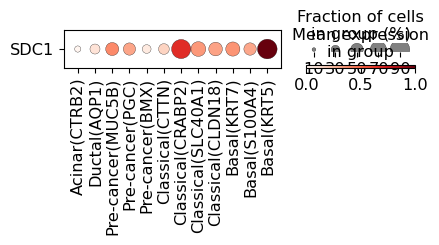

In [55]:

sc.pl.dotplot(
    adata_epi, 
    var_names='SDC1', 
    groupby='celltype2', 
    standard_scale='var',
    figsize=(4.5,0.5),
    swap_axes=True,
    save='SDC1_in_adata_epi.pdf'
)

In [19]:
epi_degenes = pd.DataFrame()
for i in adata_epi.obs.celltype2.unique():
    epi_degenes[i] = sc.get.rank_genes_groups_df(adata_epi, group=i, 
                    key='wilcoxon', pval_cutoff=0.01, log2fc_min=0)['names'].head(500)

mes_degenes = pd.DataFrame()
for i in adata_mes.obs.celltype2.unique():
    mes_degenes[i] = sc.get.rank_genes_groups_df(adata_mes, group=i, 
                    key='wilcoxon', pval_cutoff=0.01, log2fc_min=0)['names'].head(500)


In [20]:
res_ls = []
res_pairs_df = pd.DataFrame()

for epi_ct in epi_degenes.columns:
    for mes_ct in mes_degenes.columns: 
        pairs = [i for i in all_lr if i[1] in epi_degenes[epi_ct].tolist() and 
                        i[0] in mes_degenes[mes_ct].tolist()]
        pairs_num = len(pairs)
        res_ls.append([epi_ct, mes_ct, pairs_num])
        
        pairs_df = pd.DataFrame(pairs)
        pairs_df.columns=['from','to']
        pairs_df['epi_ct'] = epi_ct
        pairs_df['mes_ct'] = mes_ct
        res_pairs_df = pd.concat([res_pairs_df, pairs_df], axis=0)
        
        
res_ls = pd.DataFrame(res_ls)


In [16]:
res_pairs_df.to_csv("/home/xuquan/projects/pdac/revision/data/lr/caf2cancer_lr.txt", sep='\t', index=None)

In [21]:
res_ls2 = []
res_pairs_df2 = pd.DataFrame()

for epi_ct in epi_degenes.columns:
    for mes_ct in mes_degenes.columns: 
        pairs = [i for i in all_lr if i[0] in epi_degenes[epi_ct].tolist() and 
                        i[1] in mes_degenes[mes_ct].tolist()]
        pairs_num = len(pairs)
        res_ls2.append([epi_ct, mes_ct, pairs_num])
        
        pairs_df = pd.DataFrame(pairs)
        pairs_df.columns=['from','to']
        pairs_df['epi_ct'] = epi_ct
        pairs_df['mes_ct'] = mes_ct
        res_pairs_df2 = pd.concat([res_pairs_df2, pairs_df], axis=0)
        
        
res_ls2 = pd.DataFrame(res_ls2)


In [47]:
res_pairs_df.to_csv("/home/xuquan/projects/pdac/revision2/results/caf2cancer_lr.txt", sep='\t', index=None)

In [46]:
res_pairs_df2.to_csv("/home/xuquan/projects/pdac/revision2/results/cancer2caf_lr.txt", sep='\t', index=None)

### LR cancer-caf

In [22]:
with pd.ExcelWriter("/home/xuquan/projects/pdac/revision/results/cancer_caf_subtypes_lr_pairs.xlsx") as writer:
    res_pairs_df.to_excel(writer, sheet_name="CAF_to_Cancer", index=False)
    res_pairs_df2.to_excel(writer, sheet_name="Cancer_to_CAF", index=False)


#### caf2cancer

In [23]:
sub_lr = [i for i in all_lr if i[1] in ref_degenes['epithelial'].tolist() and 
                                 i[0] in ref_degenes['mesenchyme'].tolist()]

sub_lr = pd.DataFrame({'from':[i[0] for i in sub_lr],
                 'to':[i[1] for i in sub_lr]})


aaa = pd.DataFrame((res_pairs_df['from']+'_'+res_pairs_df['to']).value_counts()).to_dict()['count']

sub_lr['value'] = [aaa[i] if i in aaa else 0 for i in sub_lr['from']+'_'+sub_lr['to']]

sub_lr['freq'] = sub_lr['from'].map(sub_lr['from'].value_counts())
sub_lr_sorted = sub_lr.sort_values(by='freq', ascending=False).drop(columns='freq')

sub_lr['freq'] = sub_lr['to'].map(sub_lr['to'].value_counts())
sub_lr_sorted = sub_lr.sort_values(by='freq', ascending=False).drop(columns='freq')

use_genes = list(set(sub_lr['from'].tolist()+sub_lr['to'].tolist()))
# use_genes_col = many_color.many[:len(use_genes)]
# use_genes_col = ['#00A087' if i in sub_lr['from'].tolist() else '#3C5488' for i in use_genes]


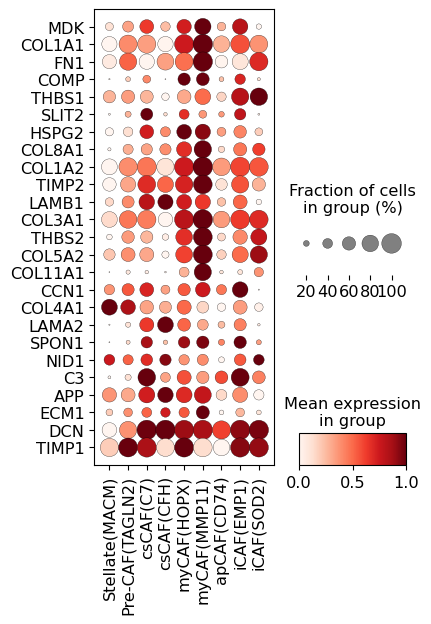

In [38]:

sc.pl.dotplot(
    adata_mes, 
    var_names=sub_lr_sorted['from'].unique(), 
    groupby='celltype2', 
    standard_scale='var',
    swap_axes=True,
    categories_order=['Stellate(MACM)', 'Pre-CAF(TAGLN2)', 'csCAF(C7)', 'csCAF(CFH)', 'myCAF(HOPX)', 'myCAF(MMP11)', 'apCAF(CD74)', 'iCAF(EMP1)', 'iCAF(SOD2)'],
    figsize=(4,6),
    save='SDC1_in_adata_mes_ligands.pdf'
)

In [27]:
sub_lr_sorted.to_csv("/home/xuquan/projects/pdac/revision2/results/sub_lr_sorted.txt", sep='\t')
with open("/home/xuquan/projects/pdac/revision2/results/use_genes.txt", 'w') as f:
    for i in use_genes:
        f.write(f"{i}\n")

In [25]:
%%R -i sub_lr_sorted -i use_genes -i use_genes_col -i figdir

col_fun = colorRamp2(range(sub_lr_sorted$value)/1.2, c("#FFFFFF", "#222222"), transparency = 0.3)

use_genes_col= unlist(use_genes_col)
names(use_genes_col) <- use_genes


# pdf("/home/xuq44/projects/scPDAC/figures/LR_Cancer_CAF_chord.pdf")

chordDiagram(sub_lr_sorted, 
             col=col_fun,
             annotationTrack = "grid", 
             preAllocateTracks = 1, 
             grid.col = use_genes_col
            )

circos.trackPlotRegion(track.index = 1, panel.fun = function(x, y) {
    xlim = get.cell.meta.data("xlim")
    ylim = get.cell.meta.data("ylim")
    sector.name = get.cell.meta.data("sector.index")
    circos.text(mean(xlim), ylim[1] + .1, sector.name, facing = "clockwise", niceFacing = TRUE, adj = c(0, 0.5))
}, bg.border = NA)


# dev.off()


UsageError: Cell magic `%%R` not found.


In [71]:
sub_lr_sorted['from_p'] = sub_lr_sorted['from'].map(allgenes_km_logpval)
sub_lr_sorted['to_p'] = sub_lr_sorted['to'].map(allgenes_km_logpval)


In [72]:
%%R -i sub_lr_sorted


library(circlize)
library(dplyr)
library(tibble)

col_fun = colorRamp2(range(sub_lr_sorted$value)/1.2, c("#FFFFFF", "#222222"), transparency = 0.3)

use_genes_col= unlist(use_genes_col)
names(use_genes_col) <- use_genes

df <- sub_lr_sorted  # assuming already loaded

# Example input df with from, to, value, from_p, to_p columns
# Filter zero value links
df_filtered <- df[df$value > 0, ]

# All genes as sectors
all_genes <- unique(c(df_filtered$from, df_filtered$to))
grid_colors <- setNames(rainbow(length(all_genes)), all_genes)

# Calculate total from and to weights per gene (sector)
from_weights <- df_filtered %>% group_by(from) %>% summarise(w = sum(value)) %>% deframe()
to_weights <- df_filtered %>% group_by(to) %>% summarise(w = sum(value)) %>% deframe()

# Make sure all genes have weights (0 if missing)
from_weights_all <- setNames(rep(0, length(all_genes)), all_genes)
from_weights_all[names(from_weights)] <- from_weights

to_weights_all <- setNames(rep(0, length(all_genes)), all_genes)
to_weights_all[names(to_weights)] <- to_weights

# from_p and to_p vectors
from_p_map <- df_filtered %>% group_by(from) %>% summarise(from_p = mean(from_p)) %>% deframe()
to_p_map <- df_filtered %>% group_by(to) %>% summarise(to_p = mean(to_p)) %>% deframe()

from_p_all <- setNames(rep(NA, length(all_genes)), all_genes)
from_p_all[names(from_p_map)] <- from_p_map

to_p_all <- setNames(rep(NA, length(all_genes)), all_genes)
to_p_all[names(to_p_map)] <- to_p_map

# Color function
heatmap_col_fun <- colorRamp2(c(0, 2), c("white", "black"))

# Clear circos and plot chordDiagram with reduce=FALSE
circos.clear()

pdf("/home/xuq44/projects/scPDAC/figures/LR_Cancer_CAF_chord.pdf")

circos.par(track.margin = c(0.01, 0.02))  # Increase margin between tracks

chordDiagram(
  df_filtered[, c("from", "to", "value")],
  col = col_fun,
  annotationTrack = "grid",
  preAllocateTracks = list(track.height = 0.05),
  grid.col = use_genes_col,
  reduce = FALSE
)

# Track 1: heatmap (keep 0.07 height)
circos.trackPlotRegion(
  track.index = 1,
  panel.fun = function(x, y) {
    sector.name <- get.cell.meta.data("sector.index")
    xlim <- get.cell.meta.data("xlim")
    total_width <- xlim[2] - xlim[1]

    w_from <- from_weights_all[sector.name]
    w_to <- to_weights_all[sector.name]
    total_w <- w_from + w_to
    if (total_w == 0) total_w <- 1
    split_pos <- xlim[1] + total_width * (w_from / total_w)

    col_from_p <- ifelse(is.na(from_p_all[sector.name]), "#CCCCCC", heatmap_col_fun(from_p_all[sector.name]))
    col_to_p <- ifelse(is.na(to_p_all[sector.name]), "#CCCCCC", heatmap_col_fun(to_p_all[sector.name]))

    if (w_from > 0) {
      circos.rect(xleft = xlim[1], xright = split_pos, ybottom = 0, ytop = 1,
                  col = col_from_p, border = NA)
    }
    if (w_to > 0) {
      circos.rect(xleft = split_pos, xright = xlim[2], ybottom = 0, ytop = 1,
                  col = col_to_p, border = NA)
    }
  },
  bg.border = NA
)

# Track 2: labels (increase height to 0.12, and lower y position)
circos.trackPlotRegion(
  track.index = 2,
  panel.fun = function(x, y) {
    sector.name <- get.cell.meta.data("sector.index")
    xlim <- get.cell.meta.data("xlim")
    ylim <- get.cell.meta.data("ylim")

    circos.text(
      x = mean(xlim),
      y = ylim[1] + (ylim[2] - ylim[1]) * 0.3,  # lowered label position
      labels = sector.name,
      facing = "clockwise",
      niceFacing = TRUE,
      adj = c(0, 0.5),
      cex = 0.7
    )
  },
  bg.border = NA,
  track.height = 0.12
)

dev.off()


png 
  2 


In [40]:
ref_degenes.to_csv("/home/xuquan/projects/pdac/revision2/results/ref_degenes.txt", sep='\t')


In [42]:
with open("/home/xuquan/projects/pdac/revision2/results/all_lr.txt", 'w') as f:
    for i,j in all_lr:
        f.write(f"{i}\t{j}\n")

In [44]:
res_pairs_df2.to_csv("/home/xuquan/projects/pdac/revision2/results/res_pairs_df2.txt", sep='\t')


#### cancer2caf

In [38]:
sub_lr = [i for i in all_lr if i[1] in ref_degenes['mesenchyme'].tolist() and 
                                 i[0] in ref_degenes['epithelial'].tolist()]

sub_lr = pd.DataFrame({'from':[i[0] for i in sub_lr],
                 'to':[i[1] for i in sub_lr]})


aaa = pd.DataFrame((res_pairs_df2['from']+'_'+res_pairs_df2['to']).value_counts()).to_dict()['count']

sub_lr['value'] = [aaa[i] if i in aaa else 0 for i in sub_lr['from']+'_'+sub_lr['to']]

sub_lr['freq'] = sub_lr['from'].map(sub_lr['from'].value_counts())
sub_lr_sorted = sub_lr.sort_values(by='freq', ascending=False).drop(columns='freq')

sub_lr['freq'] = sub_lr['to'].map(sub_lr['to'].value_counts())
sub_lr_sorted = sub_lr.sort_values(by='freq', ascending=False).drop(columns='freq')

use_genes = list(set(sub_lr['from'].tolist()+sub_lr['to'].tolist()))
# use_genes_col = many_color.many[:len(use_genes)]
# use_genes_col = ['#3C5488' if i in sub_lr['from'].tolist() else '#00A087' for i in use_genes]


In [96]:
# ref_degenes

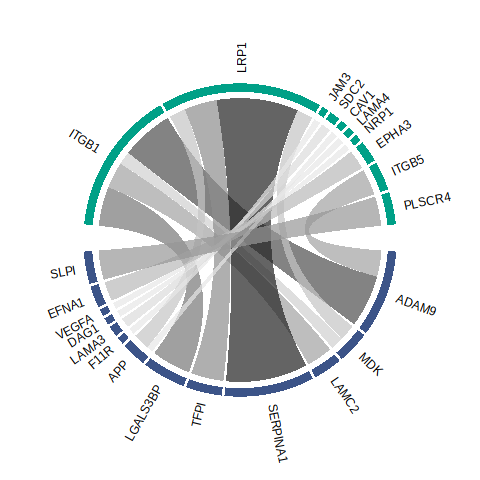

In [98]:
%%R -i sub_lr_sorted -i use_genes -i use_genes_col -i figdir

col_fun = colorRamp2(range(sub_lr_sorted$value)/1.2, c("#FFFFFF", "#222222"), transparency = 0.3)

use_genes_col= unlist(use_genes_col)
names(use_genes_col) <- use_genes


# pdf("/home/xuq44/projects/scPDAC/figures/LR_Cancer_CAF_chord.pdf")

chordDiagram(sub_lr_sorted, 
             col=col_fun,
             annotationTrack = "grid", 
             preAllocateTracks = 1, 
             grid.col = use_genes_col
            )

circos.trackPlotRegion(track.index = 1, panel.fun = function(x, y) {
    xlim = get.cell.meta.data("xlim")
    ylim = get.cell.meta.data("ylim")
    sector.name = get.cell.meta.data("sector.index")
    circos.text(mean(xlim), ylim[1] + .1, sector.name, facing = "clockwise", niceFacing = TRUE, adj = c(0, 0.5))
}, bg.border = NA)


# dev.off()


In [99]:
sub_lr_sorted['from_p'] = sub_lr_sorted['from'].map(allgenes_km_logpval)
sub_lr_sorted['to_p'] = sub_lr_sorted['to'].map(allgenes_km_logpval)


In [100]:
%%R -i sub_lr_sorted


library(circlize)
library(dplyr)
library(tibble)

col_fun = colorRamp2(range(sub_lr_sorted$value)/1.2, c("#FFFFFF", "#222222"), transparency = 0.3)

use_genes_col= unlist(use_genes_col)
names(use_genes_col) <- use_genes

df <- sub_lr_sorted  # assuming already loaded

# Example input df with from, to, value, from_p, to_p columns
# Filter zero value links
df_filtered <- df[df$value > 0, ]

# All genes as sectors
all_genes <- unique(c(df_filtered$from, df_filtered$to))
grid_colors <- setNames(rainbow(length(all_genes)), all_genes)

# Calculate total from and to weights per gene (sector)
from_weights <- df_filtered %>% group_by(from) %>% summarise(w = sum(value)) %>% deframe()
to_weights <- df_filtered %>% group_by(to) %>% summarise(w = sum(value)) %>% deframe()

# Make sure all genes have weights (0 if missing)
from_weights_all <- setNames(rep(0, length(all_genes)), all_genes)
from_weights_all[names(from_weights)] <- from_weights

to_weights_all <- setNames(rep(0, length(all_genes)), all_genes)
to_weights_all[names(to_weights)] <- to_weights

# from_p and to_p vectors
from_p_map <- df_filtered %>% group_by(from) %>% summarise(from_p = mean(from_p)) %>% deframe()
to_p_map <- df_filtered %>% group_by(to) %>% summarise(to_p = mean(to_p)) %>% deframe()

from_p_all <- setNames(rep(NA, length(all_genes)), all_genes)
from_p_all[names(from_p_map)] <- from_p_map

to_p_all <- setNames(rep(NA, length(all_genes)), all_genes)
to_p_all[names(to_p_map)] <- to_p_map

# Color function
heatmap_col_fun <- colorRamp2(c(0, 2), c("white", "black"))

# Clear circos and plot chordDiagram with reduce=FALSE
circos.clear()

pdf("/home/xuq44/projects/scPDAC/figures/LR_Cancer_CAF_chord2.pdf")

circos.par(track.margin = c(0.01, 0.02))  # Increase margin between tracks

chordDiagram(
  df_filtered[, c("from", "to", "value")],
  col = col_fun,
  annotationTrack = "grid",
  preAllocateTracks = list(track.height = 0.05),
  grid.col = use_genes_col,
  reduce = FALSE
)

# Track 1: heatmap (keep 0.07 height)
circos.trackPlotRegion(
  track.index = 1,
  panel.fun = function(x, y) {
    sector.name <- get.cell.meta.data("sector.index")
    xlim <- get.cell.meta.data("xlim")
    total_width <- xlim[2] - xlim[1]

    w_from <- from_weights_all[sector.name]
    w_to <- to_weights_all[sector.name]
    total_w <- w_from + w_to
    if (total_w == 0) total_w <- 1
    split_pos <- xlim[1] + total_width * (w_from / total_w)

    col_from_p <- ifelse(is.na(from_p_all[sector.name]), "#CCCCCC", heatmap_col_fun(from_p_all[sector.name]))
    col_to_p <- ifelse(is.na(to_p_all[sector.name]), "#CCCCCC", heatmap_col_fun(to_p_all[sector.name]))

    if (w_from > 0) {
      circos.rect(xleft = xlim[1], xright = split_pos, ybottom = 0, ytop = 1,
                  col = col_from_p, border = NA)
    }
    if (w_to > 0) {
      circos.rect(xleft = split_pos, xright = xlim[2], ybottom = 0, ytop = 1,
                  col = col_to_p, border = NA)
    }
  },
  bg.border = NA
)

# Track 2: labels (increase height to 0.12, and lower y position)
circos.trackPlotRegion(
  track.index = 2,
  panel.fun = function(x, y) {
    sector.name <- get.cell.meta.data("sector.index")
    xlim <- get.cell.meta.data("xlim")
    ylim <- get.cell.meta.data("ylim")

    circos.text(
      x = mean(xlim),
      y = ylim[1] + (ylim[2] - ylim[1]) * 0.3,  # lowered label position
      labels = sector.name,
      facing = "clockwise",
      niceFacing = TRUE,
      adj = c(0, 0.5),
      cex = 0.7
    )
  },
  bg.border = NA,
  track.height = 0.12
)

dev.off()


png 
  2 


### LR num

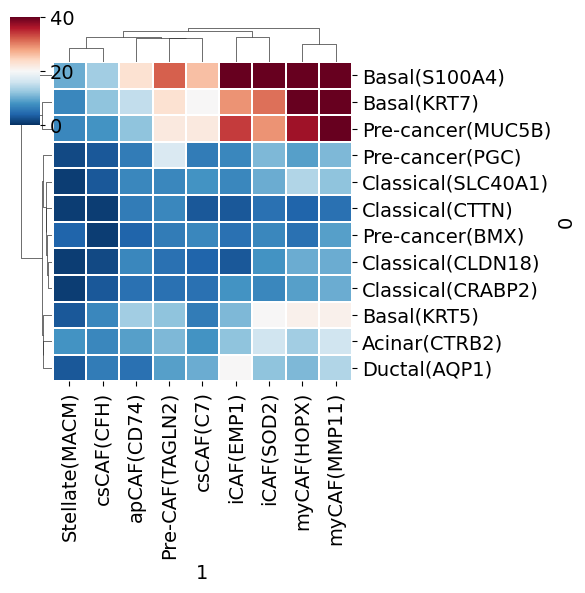

In [12]:
res_ls_df = res_ls.set_index(0).pivot(columns=1, values=2)

link1 = linkage(res_ls_df.T)
link2 = linkage(res_ls_df)

link2[10][[0,1]]=link2[10][[1,0]]
link1[7][[0,1]]=link1[7][[1,0]]

fig = sns.clustermap(res_ls_df, 
                     vmin=0, vmax=40,
                     col_linkage=link1, 
                     row_linkage=link2, 
                     row_cluster=True, 
                     col_cluster=True,
                     cmap='RdBu_r',dendrogram_ratio=0.1, colors_ratio=0.01,
                     linewidths=0.1,
                     figsize=(6,6)
                    )
fig.savefig(f"{figdir}/LR_Cancer_CAF_number.pdf")

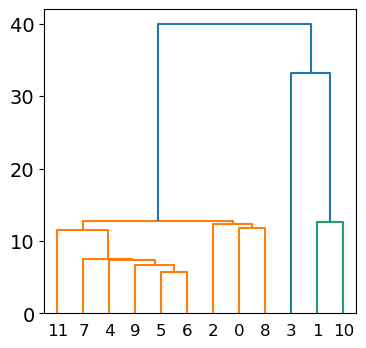

In [540]:
_ = dendrogram(link2)
# _ = dendrogram(link1)


In [92]:
res_ls_df

1,Pre-CAF(TAGLN2),Stellate(MACM),apCAF(CD74),csCAF(C7),csCAF(CFH),iCAF(EMP1),iCAF(SOD2),myCAF(HOPX),myCAF(MMP11)
0,,,,,,,,,
Acinar(CTRB2),11,8,9,8,7,12,16,13,16
Basal(KRT5),12,3,13,6,7,11,20,21,21
Basal(KRT7),23,7,15,20,12,29,31,45,46
Basal(S100A4),32,10,23,26,13,46,43,56,65
Classical(CLDN18),5,1,7,4,2,3,8,10,10
Classical(CRABP2),5,1,5,5,3,8,7,9,10
Classical(CTTN),7,1,6,3,1,3,5,4,5
Classical(SLC40A1),7,1,7,8,3,7,10,14,12
Ductal(AQP1),9,3,5,10,6,20,12,11,14


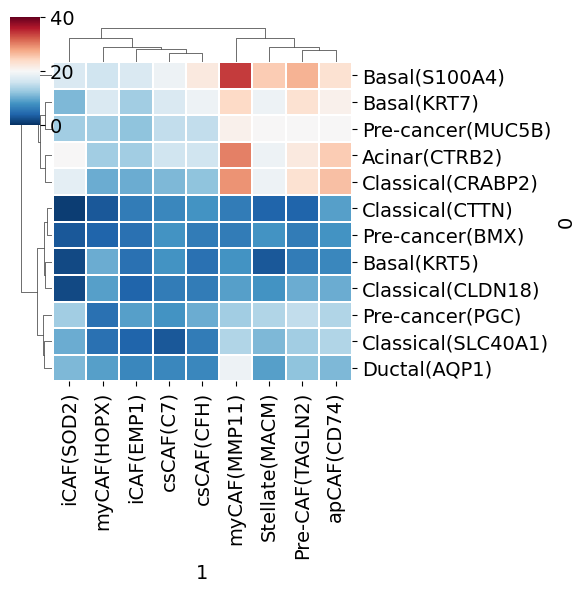

In [83]:
res_ls_df2 = res_ls2.set_index(0).pivot(columns=1, values=2)

# link1 = linkage(res_ls_df2.T)
# link2 = linkage(res_ls_df2)

# link2[10][[0,1]]=link2[10][[1,0]]
# link1[7][[0,1]]=link1[7][[1,0]]

fig = sns.clustermap(res_ls_df2, 
                      vmin=0, vmax=40,
#                      col_linkage=link1, 
#                      row_linkage=link2, 
                     row_cluster=True, 
                     col_cluster=True,
                     cmap='RdBu_r',dendrogram_ratio=0.1, colors_ratio=0.01,
                     linewidths=0.1,
                     figsize=(6,6)
                    )
fig.savefig(f"{figdir}/LR_Cancer_CAF_number2.pdf")

In [13]:
res_ls

,0,1,2
0,Basal(KRT7),Pre-CAF(TAGLN2),23
1,Basal(KRT7),Stellate(MACM),7
2,Basal(KRT7),myCAF(MMP11),46
3,Basal(KRT7),myCAF(HOPX),45
4,Basal(KRT7),iCAF(EMP1),29
...,...,...,...
103,Classical(CRABP2),iCAF(EMP1),8
104,Classical(CRABP2),apCAF(CD74),5
105,Classical(CRABP2),csCAF(C7),5
106,Classical(CRABP2),iCAF(SOD2),7
